# TVA Grid Sensor Placement: QVIDIA

## Our Hybrid Approach

We decided to use QAOA to choose optimal placing of sensors that minimizes the number of sensors needed to completely
cover the graph. To help utilities like TVA have an in-depth understanding of the grid, we will use a quantum-classical hybrid approach to find the best sensor placement locations. While QAOA narrows down the search space to options where the minimum number of needed sensors are being used, a conventional computing approach will be used to search which of the remaining options places the most MW load under redunant sensing. Later, we will use QAOA to narrow down configurations that use more than the minimum number of needed sensors and still keep coverage of the whole grid. We will evaluate these to determine how redundancy changes as more sensors are added.

In [1]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import time
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from scipy.optimize import milp, LinearConstraint, Bounds, minimize

# check.py sits next to this notebook: it loads the grids and checks placements
from check import load_grid, seen_buses, check_placement, brute_force_best, bits_to_buses

sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


## 1. Load and draw the grid

The grids get loaded and drawn. Alongside the 14 and 6-piece, we created a second 6-piece that has a more challenging structure to it. This is in data/ieee14_piece6_2.json

IEEE 14-bus | 14 buses, 20 lines
IEEE 14-bus, 6-substation piece | buses [2, 3, 5, 6, 10, 11]


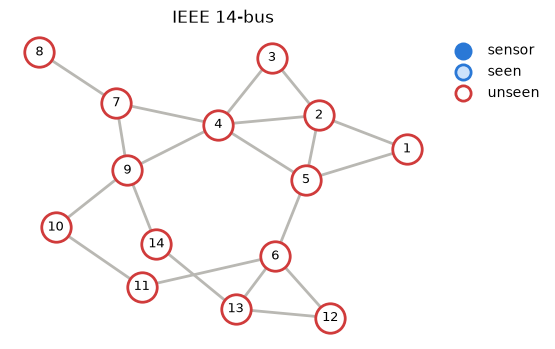

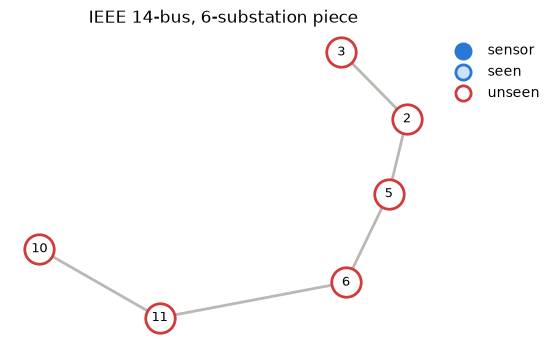

In [2]:
grid = load_grid("data/ieee14.json")
piece = load_grid("data/ieee14_piece6.json")
piece6_2 = load_grid("data/ieee14_piece6_2.json")
print(grid["name"], "|", len(grid["buses"]), "buses,", len(grid["lines"]), "lines")
print(piece["name"], "| buses", piece["buses"])


def layout(g):
    # networkx is only used to lay out the drawing; without it, buses go on a circle
    try:
        import networkx as nx
        return nx.kamada_kawai_layout(nx.Graph(g["lines"]))
    except ImportError:
        angle = np.linspace(0, 2 * np.pi, len(g["buses"]), endpoint=False)
        return {b: (np.cos(a), np.sin(a)) for b, a in zip(g["buses"], angle)}


def draw_grid(g, chosen=(), title="", pos=None):
    pos = pos or layout(g)
    seen = seen_buses(g, chosen)
    fig, ax = plt.subplots(figsize=(5.5, 4))
    for a, b in g["lines"]:
        ax.plot(*zip(pos[a], pos[b]), color="#b9b8b3", lw=2, zorder=1)
    for b in g["buses"]:
        face = "#2a78d6" if b in chosen else ("#cde2fb" if b in seen else "white")
        ring = "#2a78d6" if b in seen else "#d03b3b"
        ax.scatter(*pos[b], s=450, c=face, edgecolors=ring, linewidths=2, zorder=2)
        ax.annotate(str(b), pos[b], ha="center", va="center", fontsize=9, zorder=3,
                    color="white" if b in chosen else "black")
    for label, face, ring in [("sensor", "#2a78d6", "#2a78d6"), ("seen", "#cde2fb", "#2a78d6"), ("unseen", "white", "#d03b3b")]:
        ax.scatter([], [], s=120, c=face, edgecolors=ring, linewidths=2, label=label)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    ax.set_title(title or g["name"])
    ax.margins(0.08)
    ax.axis("off")
    plt.show()


pos14 = layout(grid)              # one layout, so the piece sits where it is in the full grid
draw_grid(grid, pos=pos14)
draw_grid(piece, pos=pos14)


Below is the modified 6-bus system that we created to perform additional testing on our algorithm. We needed something slightly more complicated than the linear 6-bus system provided

IEEE 14-bus, 6 piece 2 | buses [1, 2, 3, 4, 5, 7] | 8 lines
ILP answer: (run Milestone 2 first)


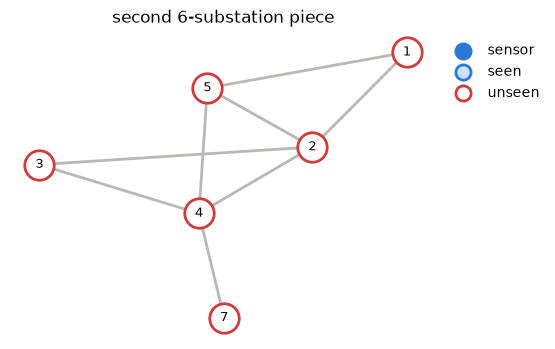

In [3]:
piece6_2 = load_grid("data/ieee14_piece6_2.json")
print(piece6_2["name"], "| buses", piece6_2["buses"], "|", len(piece6_2["lines"]), "lines")
print("ILP answer:", ilp_placement(piece6_2) if "ilp_placement" in globals() else "(run Milestone 2 first)")
draw_grid(piece6_2, title="second 6-substation piece")

## Milestone 1: place sensors by hand

Below our guess is that an optimal solution can be done with 4 nodes. For example, 7, 2, 13, and 10.

IEEE 14-bus | rules: see neighbors | sensors at [2, 7, 10, 13]
  VALID with 4 sensors, redundancy 16
  if the sensor at any of [2, 7, 10, 13] fails, some bus goes unseen


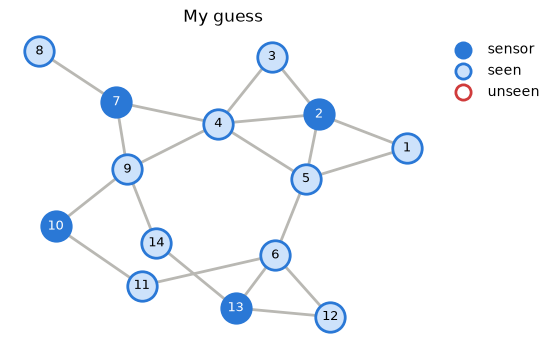

In [4]:
my_guess = [7, 2, 13, 10]
check_placement(grid, my_guess)
draw_grid(grid, my_guess, "My guess", pos=pos14)

## Milestone 2: classical baselines

First, define the greedy placement algorithm to as a baseline for this problem. Then, define ILP (integer linear programming). Both will be used to benchmark our QAOA.
1. Greedy - runs through all possible solutions to a problem
2. ILP - uses linear constraints to arrive at solution

In [5]:
def greedy_placement(g):
    # Add sensors one at a time, always at the bus that sees the most unseen buses.
    chosen = []
    unseen = set(g["buses"])

    # chooses a b who is at least tied for the max number of neighbors
    while len(unseen) != 0:
        b = [i for i in unseen if len(g["neighbors"][i]) == max([len(g["neighbors"][j]) for j in unseen])][0]
        
        unseen.remove(b)
        chosen.append(b)
    
    return chosen

greedy: [2, 5, 6, 11, 3, 10] in 0.0 ms
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 3, 5, 6, 10, 11]
  VALID with 6 sensors, redundancy 16
  survives any single sensor failure

ILP: [2, 11] in 12.0 ms
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen

greedy: [4, 2, 5, 6, 9, 7, 13, 1, 3, 10, 11, 12, 14, 8] in 0.1 ms
IEEE 14-bus | rules: see neighbors | sensors at [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
  VALID with 14 sensors, redundancy 54
  survives any single sensor failure

ILP: [2, 7, 11, 13] in 9.8 ms
IEEE 14-bus | rules: see neighbors | sensors at [2, 7, 11, 13]
  VALID with 4 sensors, redundancy 16
  if the sensor at any of [2, 7, 11, 13] fails, some bus goes unseen



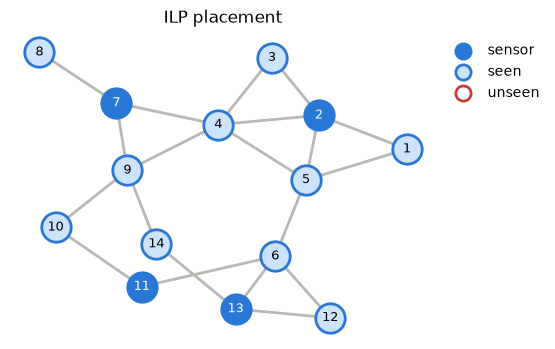

In [6]:
def ilp_placement(g, twice=False):
    # Exact minimum: one 0/1 variable per bus, and for every bus
    # (sensors on it or its neighbors) >= 1, or >= 2 with twice=True (N-1 stretch)
    buses = g["buses"]
    A = np.array([[1 if c == b or c in g["neighbors"][b] else 0 for c in buses] for b in buses])
    res = milp(c=np.ones(len(buses)), constraints=LinearConstraint(A, lb=2 if twice else 1),
               integrality=np.ones(len(buses)), bounds=Bounds(0, 1))
    return [b for b, x in zip(buses, res.x) if x > 0.5]


for g in [piece, grid]:
    for name, method in [("greedy", greedy_placement), ("ILP", ilp_placement)]:
        try:
            t0 = time.perf_counter()
            chosen = method(g)
            ms = 1000 * (time.perf_counter() - t0)
        except NotImplementedError:
            print(f"{name}: TODO\n")
            continue
        print(f"{name}: {chosen} in {ms:.1f} ms")
        check_placement(g, chosen)
        print()

draw_grid(grid, ilp_placement(grid), "ILP placement", pos=pos14)

## Milestone 3: the cost function

QAOA will look for the bitstring with the lowest cost

$$C(x) = \underbrace{\sum_b x_b}_{\text{sensors}} \; + \; P \sum_b \underbrace{\prod_{j \in N[b]} (1 - x_j)}_{1 \text{ if bus } b \text{ is unseen}}$$

where $N[b]$ is bus $b$ plus its neighbors (its "group"). The product is 1 only when every bus in the group has no sensor, which is exactly when bus $b$ is unseen.

**Pick $P > 1$**, so an unseen bus costs more than one sensor. Then leaving a bus unseen always costs more than adding a sensor that sees it, so the cheapest bitstring is a valid placement with the fewest sensors. We use $P = 2$.

Why this form: it needs exactly one qubit per bus. The textbook QUBO (a cost with only pairs of 0/1 variables) turns each "at least one sensor" rule into an equation with extra slack qubits, about three times as many qubits for IEEE 14 (46 instead of 14).

**Bit order:** in this notebook a bitstring like `"010010"` lists qubit 0 first, so character `i` is bus `g["buses"][i]`. Qiskit prints qubit 0 *last*; the provided helpers handle the flip.

**FOR US:** We wanted a cost function that prioritized having all buses within the coverage range of at least 1 sensor, then priorizing redundant coverage of high MW loads

In [7]:
def bus_groups(g):
    index = {b: i for i, b in enumerate(g["buses"])}
    return [sorted(index[c] for c in {b} | g["neighbors"][b]) for b in g["buses"]]

# default penalty for each unseen bus
P = 2

def placement_cost(bits, g, P=P):
    
    # C(x) = number of sensors + P * number of unseen buses. bits[i] is "0" or "1" for qubit i.

    # split into groups
    x = [int(c) for c in bits]
    groups = bus_groups(g)
    
    # unseen is 1 for each node which has a group of all 0s
    unseen = sum(1 for i in groups if all(x[j] == 0 for j in i))

    return sum(x) + P * unseen


## Comparing ILP with custom cost function

Here you can see how they match up for picking the best option for the 3 graphs.

Cheapest bitstring by your cost function -> [2, 11] | cost 2
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen
ILP answer: [2, 11]


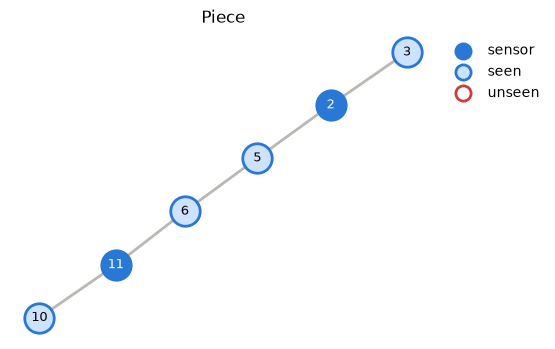

Cheapest bitstring by your cost function -> [1, 4] | cost 2
IEEE 14-bus, 6 piece 2 | rules: see neighbors | sensors at [1, 4]
  VALID with 2 sensors, redundancy 8
  if the sensor at any of [1, 4] fails, some bus goes unseen
ILP answer: [2, 11]


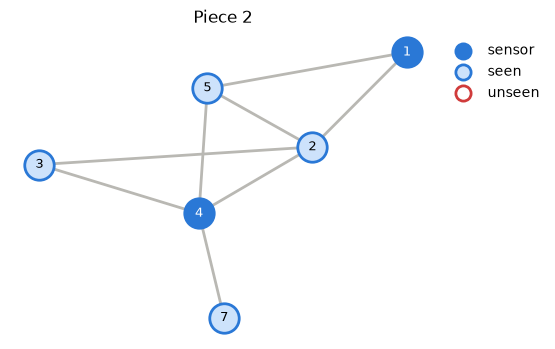

Cheapest bitstring by your cost function -> [2, 6, 7, 9] | cost 4
IEEE 14-bus | rules: see neighbors | sensors at [2, 6, 7, 9]
  VALID with 4 sensors, redundancy 19
  if the sensor at any of [2, 6, 7, 9] fails, some bus goes unseen
ILP answer: [2, 7, 11, 13]


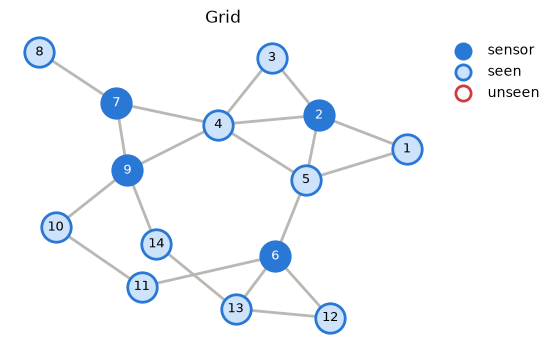

In [8]:
def cost_table(g, P=P):
    # Cost of every bitstring, in the order of Qiskit's statevector: bit i of index z is qubit i.
    # format(z, "06b") puts qubit 0 last (Qiskit style), so [::-1] puts it first (our style).
    n = len(g["buses"])
    return np.array([placement_cost(format(z, f"0{n}b")[::-1], g, P) for z in range(2 ** n)])


# 6-piece

# calc minimum cost
costs6 = cost_table(piece, 2)
z = int(np.argmin(costs6))

# convert to bus nums
cheapest = bits_to_buses(piece, format(z, "06b")[::-1])

# show
print("Cheapest bitstring by your cost function ->", cheapest, "| cost", costs6[z])
check_placement(piece, cheapest)
print("ILP answer:", ilp_placement(piece))
draw_grid(piece, cheapest, "Piece")


# 6-piece 2 

# calc minimum cost
costs6_2 = cost_table(piece6_2, 2)
z = int(np.argmin(costs6_2))

# convert to bus nums
cheapest = bits_to_buses(piece6_2, format(z, "06b")[::-1])

# show
print("Cheapest bitstring by your cost function ->", cheapest, "| cost", costs6_2[z])
check_placement(piece6_2, cheapest)
print("ILP answer:", ilp_placement(piece))
draw_grid(piece6_2, cheapest, "Piece 2")


# 14 piece

# calc minimum cost
costs14 = cost_table(grid, 2)
z = int(np.argmin(costs14))

# convert to bus nums
cheapest = bits_to_buses(grid, format(z, "06b")[::-1])

# show
print("Cheapest bitstring by your cost function ->", cheapest, "| cost", costs14[z])
check_placement(grid, cheapest)
print("ILP answer:", ilp_placement(grid))
draw_grid(grid, cheapest, "Grid")


## Milestone 4: QAOA

QAOA starts with every qubit in $|+\rangle$ (all placements at once) and repeats two layers `layers` times:
- **cost layer** 
- **mixer layer**

A classical optimizer tunes the angles $\gamma, \beta$ (provided). The cost layer has two kinds of terms:
1. **Sensor cost** $x_b$: a phase $e^{-i\gamma}$ when qubit $i$ is 1. That is `qc.p(-gamma, i)`.
2. **Unseen penalty** $P \prod_{j \in N[b]} (1 - x_j)$: a phase $e^{-i\gamma P}$ only when every qubit in the group is 0. A multi-controlled phase `mcp` fires only when all its qubits are 1, so flip the group with X gates, apply `mcp`, and flip back.

This keeps the circuit at one qubit per bus with no extra qubits.

In [9]:
def cost_layer(qc, g, gamma, P=P, valid_only=False):
    
    groups = bus_groups(g)

    # Unseen penalty
    for grp in groups:

        # apply not, phase if all one, apply not
        qc.x(grp)
        qc.mcp(-gamma * P, grp[:-1], grp[-1])
        qc.x(grp)

    # Sensor cost: for every qubit i, qc.p(-gamma, i)
    for i in range(len(g["buses"])):
        qc.p(-gamma, i)

def check_cost_layer(g, gamma=0.37):
    # Compare your circuit's phases with exp(-i * gamma * C) from placement_cost.
    n = len(g["buses"])
    qc = QuantumCircuit(n)
    qc.h(range(n))
    cost_layer(qc, g, gamma)
    qc.save_statevector()
    state = np.asarray(sim.run(transpile(qc, sim)).result().get_statevector())
    ratio = state / (np.exp(-1j * gamma * cost_table(g)) / np.sqrt(2 ** n))
    ok = np.allclose(ratio, ratio[0], atol=1e-6)   # equal up to one global phase
    print(g["name"], "| cost layer matches your cost function:", ok)
    return ok


check_cost_layer(piece)

IEEE 14-bus, 6-substation piece | cost layer matches your cost function: True


True

### The QAOA loop

In [10]:
def qaoa_circuit(g, params, P=P, measure=False):
    # params = [gamma_1 .. gamma_L, beta_1 .. beta_L]
    L = len(params) // 2
    n = len(g["buses"])
    qc = QuantumCircuit(n, n) if measure else QuantumCircuit(n)
    qc.h(range(n))
    for gamma, beta in zip(params[:L], params[L:]):
        cost_layer(qc, g, gamma, P, valid_only=False)
        qc.rx(2 * beta, range(n))          # mixer
    if measure:
        qc.measure(range(n), range(n))
    else:
        qc.save_statevector()
    return qc


def qaoa_probs(g, params, P=P):
    # Exact chance of every bitstring (index z: bit i of z is qubit i)
    state = sim.run(transpile(qaoa_circuit(g, params, P), sim)).result().get_statevector()
    return np.abs(np.asarray(state)) ** 2


def score(probs, costs, alpha):
    # Average cost over the cheapest `alpha` share of outcomes (alpha=1: plain average)
    order = np.argsort(costs)
    pr, c = probs[order], costs[order]
    take = np.clip(alpha - (np.cumsum(pr) - pr), 0, pr)
    return take @ c / alpha

# used to tune gamma and beta without building the cost table: score only the bitstrings we measure
def sampled_score(g, params, P=P, alpha=0.25, shots=200, seed=None):

    # create the qaoa circuit
    qc = qaoa_circuit(g, params, P, measure=True)

    # do a set number of shots and grab the results
    counts = sim.run(transpile(qc, sim), shots=shots, seed_simulator=seed).result().get_counts()

    # tally up the results to estimate best angels gamma and beta
    samples = []
    for key, c in counts.items():
        samples += [placement_cost(key.replace(" ", "")[::-1], g, P)] * c   # key[::-1]: Qiskit order -> ours
    samples = np.sort(samples)
    return samples[:max(1, int(alpha * len(samples)))].mean()   # CVaR: mean of the best alpha share

# same as run qaoa, but doesn't calculate full cost table, just estimates hyperparams based on a set number of shots
def run_qaoa_sampled(g, layers=1, P=P, alpha=0.25, shots=200, maxiter=60, seed=7):

    # calculate hyperparams
    objective = lambda params: sampled_score(g, params, P, alpha, shots, seed)
    k = (np.arange(layers) + 0.5) / layers
    starts = [np.concatenate([k * a, (1 - k) * b]) for a, b in [(0.2, 0.2), (0.3, 0.6), (0.6, 0.3), (0.4, 0.4)]]
    x0 = min(starts, key=objective)
    result = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    
    # build and run circuits
    qc = qaoa_circuit(g, result.x, P, measure=True)
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()

    # compile results
    counts = {key.replace(" ", "")[::-1]: c for key, c in counts.items()}   # our bit order from here on
    best = min(counts, key=lambda b: placement_cost(b, g, P))
    return result.x, counts, bits_to_buses(g, best)


def counts_to_probs(g, counts):
    # For grading charts only (builds a 2^n array): counts in our bit order -> share of shots per index z
    probs = np.zeros(2 ** len(g["buses"]))
    for bits, c in counts.items():
        probs[int(bits[::-1], 2)] += c   # bits[::-1] puts qubit 0 last, so bit i of z is qubit i
    return probs / probs.sum()


def run_qaoa(g, layers=1, P=P, alpha=0.25, maxiter=100):
    costs = cost_table(g, P)
    objective = lambda params: score(qaoa_probs(g, params, P), costs, alpha)
    k = (np.arange(layers) + 0.5) / layers
    # a few "ramp" starts (gamma grows, beta shrinks, like a slow anneal); keep the best
    starts = [np.concatenate([k * a, (1 - k) * b]) for a, b in [(0.2, 0.2), (0.3, 0.6), (0.6, 0.3), (0.4, 0.4)]]
    x0 = min(starts, key=objective)
    result = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, qaoa_probs(g, result.x, P)


def outcome_shares(g, probs):
    # Split the probability into: optimal, valid with extra sensors, leaves a bus unseen
    n = len(g["buses"])
    z = np.arange(2 ** n)
    sensors = sum((z >> i) & 1 for i in range(n))
    unseen = sum((z & sum(1 << j for j in grp)) == 0 for grp in bus_groups(g))
    best, _ = brute_force_best(g)
    valid = unseen == 0
    return {"optimal": probs[valid & (sensors == best)].sum(),
            "valid, extra sensors": probs[valid & (sensors > best)].sum(),
            "leaves a bus unseen": probs[~valid].sum()}

def plot_outcomes(rows, title):
    colors = {"optimal": "#0ca30c", "valid, extra sensors": "#fab219", "leaves a bus unseen": "#d03b3b"}
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(rows) + 1.2))
    labels = list(rows)[::-1]
    left = np.zeros(len(labels))
    for kind, color in colors.items():
        vals = np.array([rows[r][kind] for r in labels])
        ax.barh(labels, vals, left=left, color=color, edgecolor="white", linewidth=2, label=kind)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v > 0.06:
                ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9)
        left += vals
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of shots")
    ax.set_title(title, pad=26)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.show()
    for r, s in rows.items():
        print(f"{r:28s}" + "  ".join(f"{k}: {v:6.2%}" for k, v in s.items()))

### Aer, exact tuning (`run_qaoa`): 6-piece #2 and 14 buses

The Aer simulation of our custom piece and the whole 14 bus graph. This section uses the run function with full cost table estimation to tune hyperparameters, which is a $ O(2^n) $ operation. Note the top probabilites are high and yet there are still some solutions that leave nodes unseen. This is a tradeoff. As P is increased, it pushes more invalid solution out of the top rankings but then cares less about the number of sensors being used, sometimes even allowing solutions with more sensors to rise above more efficient solutions.

6-piece #2: 5.3 s, angles [-0.193  0.363  0.9    0.548  0.208 -0.611]
0           14.2%  sensors at [4]  ->  NOT valid: buses [1] unseen
1           9.6%  sensors at [2, 4]  ->  valid
2           9.1%  sensors at [2, 7]  ->  valid
3           8.8%  sensors at [7]  ->  NOT valid: buses [1, 2, 3, 5] unseen
4           6.7%  sensors at [5]  ->  NOT valid: buses [3, 7] unseen
5           6.3%  sensors at [1, 4]  ->  valid
6           5.1%  sensors at [4, 5]  ->  valid
7           4.7%  sensors at [1]  ->  NOT valid: buses [3, 4, 7] unseen
8           4.5%  sensors at [2]  ->  NOT valid: buses [7] unseen
9           3.4%  sensors at [3, 7]  ->  NOT valid: buses [1, 5] unseen
Most likely valid answer: [2, 4] | ILP answer: [2, 4]


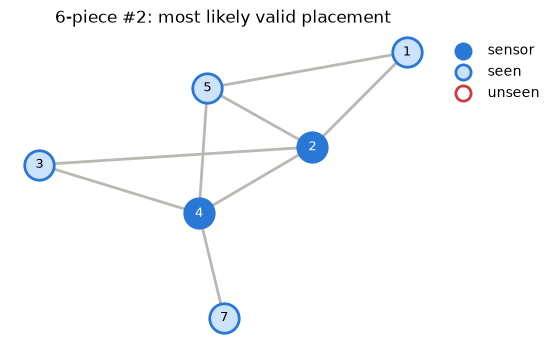

In [11]:
# params
layers6_2 = 3
P6_2 = 2

# run
t0 = time.perf_counter()
params6_2, probs6_2 = run_qaoa(piece6_2, layers=layers6_2, P=P6_2)   # exact probabilities (cost table + statevector)
print(f"6-piece #2: {time.perf_counter() - t0:.1f} s, angles {np.round(params6_2, 3)}")

# aggregate results
best6_2 = None
for idx, z in enumerate(np.argsort(probs6_2)[::-1][:10]):   # most likely answers: not all are valid
    buses = bits_to_buses(piece6_2, format(z, '06b')[::-1])
    r = check_placement(piece6_2, buses, show=False)
    if r["valid"] and best6_2 is None:
        best6_2 = buses                                      # most likely valid placement
    print(f"{str(idx).ljust(10)}  {probs6_2[z]:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))
if best6_2 is None:                                          # no valid answer in the top 15: show the most likely one
    best6_2 = bits_to_buses(piece6_2, format(np.argmax(probs6_2), '06b')[::-1])
print("Most likely valid answer:", best6_2, "| ILP answer:", ilp_placement(piece6_2))

draw_grid(piece6_2, best6_2, "6-piece #2: most likely valid placement")

14 buses: 22.2 s, angles [ 0.22  -0.395 -0.723 -0.512  0.763  0.859  1.207  0.378  0.498  0.451
 -0.284 -0.236]
0           6.7%  sensors at [2, 6, 7, 9]  ->  valid
1           5.5%  sensors at [2, 6, 8, 9]  ->  valid
2           4.2%  sensors at [2, 7, 11, 13]  ->  valid
3           4.1%  sensors at [2, 7, 10, 13]  ->  valid
4           3.3%  sensors at [2, 6, 9]  ->  NOT valid: buses [8] unseen
5           2.0%  sensors at [2, 8, 10, 13]  ->  valid
6           0.8%  sensors at [4, 7, 11, 13]  ->  NOT valid: buses [1] unseen
7           0.8%  sensors at [4, 5, 6, 7, 9]  ->  valid
8           0.8%  sensors at [6, 7, 9]  ->  NOT valid: buses [1, 2, 3] unseen
9           0.8%  sensors at [8, 10, 13]  ->  NOT valid: buses [1, 2, 3, 4, 5] unseen
Most likely valid answer: [2, 6, 7, 9] | ILP answer: [2, 7, 11, 13]


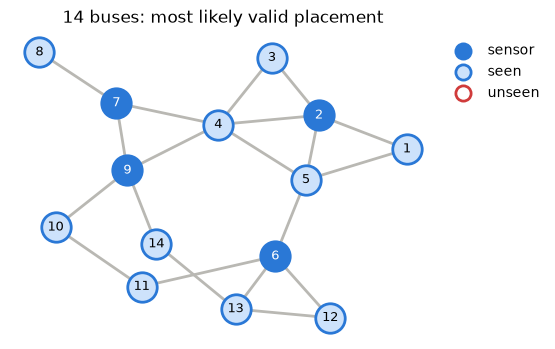

In [12]:
# params
layers14 = 6
P14 = 1.3

# run
t0 = time.perf_counter()
params14, probs14 = run_qaoa(grid, layers=layers14, P=P14, alpha=0.25)   # exact probabilities (cost table + statevector)
print(f"14 buses: {time.perf_counter() - t0:.1f} s, angles {np.round(params14, 3)}")

# aggregate results
best14 = None
for idx, z in enumerate(np.argsort(probs14)[::-1][:10]):   # most likely answers: not all are valid
    buses = bits_to_buses(grid, format(z, '014b')[::-1])
    r = check_placement(grid, buses, show=False)
    if r["valid"] and best14 is None:
        best14 = buses                                      # most likely valid placement
    print(f"{str(idx).ljust(10)}  {probs14[z]:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))
if best14 is None:                                          # no valid answer in the top 20: show the most likely one
    best14 = bits_to_buses(grid, format(np.argmax(probs14), '014b')[::-1])
print("Most likely valid answer:", best14, "| ILP answer:", ilp_placement(grid))

draw_grid(grid, best14, "14 buses: most likely valid placement", pos=pos14)

### Aer, sampled tuning (`run_qaoa_sampled`): 6-piece #2 and 14 buses

The Aer simulation of our custom piece and the whole 14 bus graph. This section uses the run function that estimates good values for the hyperparameters beta and gamma by running a set number of preliminary shots. Note that this reduces the complexity of hyperparamter tuning down to constant time, but hurts performance to an extent

6-piece #2: 1.6 s, angles [-0.723  0.296]
Cheapest measured placement: [2, 7] | ILP answer: [2, 4]
0           7.4%  sensors at [4, 5]  ->  valid
1           7.0%  sensors at [2, 7]  ->  valid
2           6.1%  sensors at [2, 4]  ->  valid
3           4.7%  sensors at [1, 3, 7]  ->  valid
4           4.4%  sensors at [1, 4]  ->  valid
5           4.3%  sensors at [3, 5, 7]  ->  valid
6           3.8%  sensors at [1, 3, 4]  ->  valid
7           3.4%  sensors at [3, 4, 5]  ->  valid
8           3.3%  sensors at [2, 5, 7]  ->  valid
9           2.9%  sensors at [7]  ->  NOT valid: buses [1, 2, 3, 5] unseen
10          2.9%  sensors at [1, 4, 7]  ->  valid
11          2.8%  sensors at [4, 5, 7]  ->  valid
12          2.7%  sensors at [1, 2, 7]  ->  valid
13          2.5%  sensors at [2, 3, 4]  ->  valid
14          2.3%  sensors at [3, 7]  ->  NOT valid: buses [1, 5] unseen


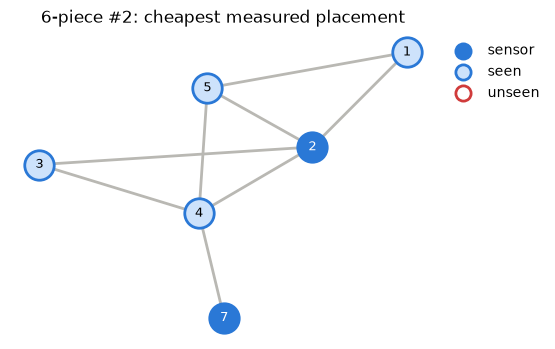

In [13]:
# hyperparams
layers6_2 = 1
P6_2 = 2
SHOTS = 1000

# run circuit
t0 = time.perf_counter()
params6_2, counts6_2, best6_2 = run_qaoa_sampled(piece6_2, layers=layers6_2, P=P6_2, shots=SHOTS)
probs6_2 = counts_to_probs(piece6_2, counts6_2)   # only for the outcome charts below
print(f"6-piece #2: {time.perf_counter() - t0:.1f} s, angles {np.round(params6_2, 3)}")

# aggregate results
print("Cheapest measured placement:", best6_2, "| ILP answer:", ilp_placement(piece6_2))
shots6_2 = sum(counts6_2.values())
for idx, (bits, c) in enumerate(sorted(counts6_2.items(), key=lambda kv: -kv[1])[:15]):   # most measured answers: not all are valid
    buses = bits_to_buses(piece6_2, bits)
    r = check_placement(piece6_2, buses, show=False)
    print(f"{str(idx).ljust(10)}  {c / shots6_2:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

draw_grid(piece6_2, best6_2, "6-piece #2: cheapest measured placement")

## 14 bus testing the likelihood of finding the optimal solution

We wanted to do a more in-depth analysis of this test to see what is the probability of actually getting the optimal solution that we are calculating later in the notebook based on which solutions place the highest amount of load under redundant sensing.

The optimal soution which maximizes load redundency while using the minimum number of nodes requires placement of nodes at busses {2, 6, 7, 9}. If it shows up in at least 1 shot the postprocessing will determine it is the optimal solution. The Aer simulation below shows that with 1000 pre-shots for hyperparamter tuning, the algorithm would read out that answer 5.5% of the time with no noise. This makes the probability of not finding the optimal solution:
$$ P(\neg\text{optimal} | \text{200Shots}) = (1 - P(optimal)) ^ {200} = 0.945 ^ {200} \approx 99.999\% $$
Worth noting here is that this will not always be the case. Even with no noise, if the optimal solution could have been {2, 8, 10, 13} based on the mw loads, which would only read out about 1.6% of the time. In that case:
$$ P(\neg\text{optimal} | \text{200Shots}) = (1 - P(optimal)) ^ {200} = 0.984 ^ {200} \approx 96.028\% $$

14 buses: 6.2 s, angles [-0.284 -0.318 -0.561  0.081  0.568  0.96   0.299  0.384  0.597 -0.3
  0.047 -0.366]
Algorithm favored answer:  [2, 7, 10, 13] | ILP answer: [2, 7, 11, 13]
0           4.7%  sensors at [2, 6, 7, 9]  ->  valid
1           4.6%  sensors at [2, 6, 8, 9]  ->  valid
2           2.1%  sensors at [2, 7, 11, 13]  ->  valid
3           1.7%  sensors at [2, 7, 13]  ->  NOT valid: buses [10, 11] unseen
4           1.6%  sensors at [2, 7, 10, 13]  ->  valid
5           1.6%  sensors at [2, 8, 10, 13]  ->  valid
6           1.1%  sensors at [1, 4, 6, 7, 9]  ->  valid
7           0.9%  sensors at [3, 5, 6, 8, 9]  ->  valid
8           0.8%  sensors at [4, 5, 6, 8, 9]  ->  valid
9           0.8%  sensors at [2, 7, 9]  ->  NOT valid: buses [6, 11, 12, 13] unseen


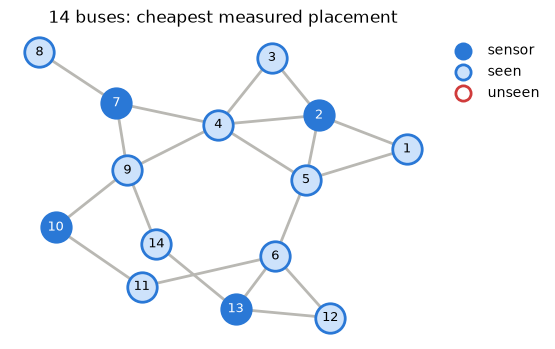

In [14]:
# hyperparams
layers14 = 6
P14 = 2
SHOTS = 1000
A = 0.25

# run circuit
t0 = time.perf_counter()
params14, counts14, best14 = run_qaoa_sampled(grid, layers=layers14, P=P14, alpha=A, shots=SHOTS)
probs14 = counts_to_probs(grid, counts14)   # only for the outcome charts below
print(f"14 buses: {time.perf_counter() - t0:.1f} s, angles {np.round(params14, 3)}")

# aggregate results
print("Algorithm favored answer: ", best14, "| ILP answer:", ilp_placement(grid))
shots14 = sum(counts14.values())
for idx, (bits, c) in enumerate(sorted(counts14.items(), key=lambda kv: -kv[1])[:10]):   # most measured answers: not all are valid
    buses = bits_to_buses(grid, bits)
    r = check_placement(grid, buses, show=False)
    print(f"{str(idx).ljust(10)}  {c / shots14:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

draw_grid(grid, best14, "14 buses: cheapest measured placement", pos=pos14)

14 buses (exact tuning): 21.0 s, angles [-0.148 -0.386 -0.479 -0.47   0.713  0.661  0.605  0.278  0.419  0.295
 -0.131 -0.296]
0           6.3%  sensors at [2, 6, 7, 9]  ->  valid
1           5.7%  sensors at [2, 6, 8, 9]  ->  valid
2           3.4%  sensors at [2, 7, 11, 13]  ->  valid
3           2.6%  sensors at [2, 8, 10, 13]  ->  valid
4           2.4%  sensors at [2, 7, 10, 13]  ->  valid
5           1.2%  sensors at [4, 5, 6, 7, 9]  ->  valid
6           1.2%  sensors at [2, 7, 13]  ->  NOT valid: buses [10, 11] unseen
7           1.1%  sensors at [4, 5, 6, 8, 9]  ->  valid
8           1.0%  sensors at [1, 4, 6, 7, 9]  ->  valid
9           1.0%  sensors at [1, 4, 6, 8, 9]  ->  valid
10          0.9%  sensors at [2, 6, 7, 11, 14]  ->  valid
11          0.9%  sensors at [3, 5, 6, 7, 9]  ->  valid
12          0.9%  sensors at [4, 5, 7, 11, 13]  ->  valid
13          0.9%  sensors at [4, 5, 7, 10, 13]  ->  valid
14          0.9%  sensors at [2, 10, 13]  ->  NOT valid: buses [7, 8] 

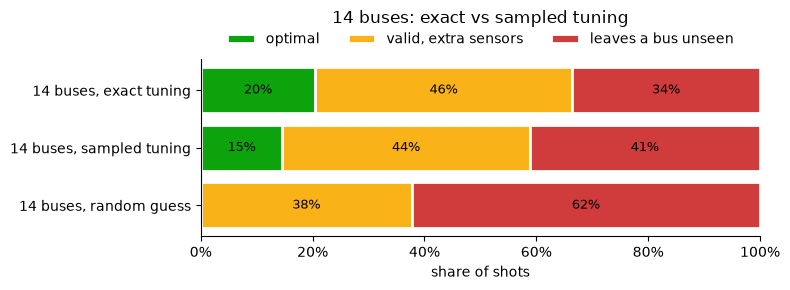

14 buses, exact tuning      optimal: 20.46%  valid, extra sensors: 45.93%  leaves a bus unseen: 33.61%
14 buses, sampled tuning    optimal: 14.60%  valid, extra sensors: 44.20%  leaves a bus unseen: 41.20%
14 buses, random guess      optimal:  0.03%  valid, extra sensors: 37.70%  leaves a bus unseen: 62.27%


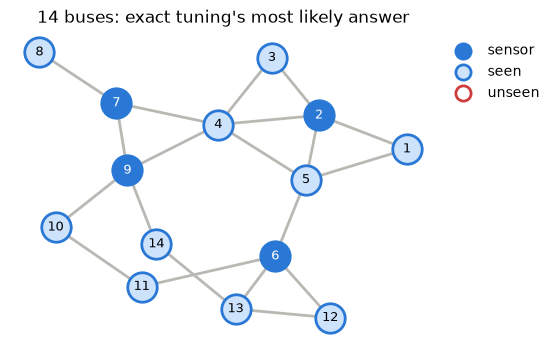

In [15]:
# Same run with the old exact tuning (run_qaoa: cost table + statevector). Separate names, so the sampled results stay.
t0 = time.perf_counter()
params14_exact, probs14_exact = run_qaoa(grid, layers=layers14, P=P14, alpha=0.2)
print(f"14 buses (exact tuning): {time.perf_counter() - t0:.1f} s, angles {np.round(params14_exact, 3)}")
for idx, z in enumerate(np.argsort(probs14_exact)[::-1][:20]):   # most likely answers: not all are valid
    buses = bits_to_buses(grid, format(z, '014b')[::-1])
    r = check_placement(grid, buses, show=False)
    print(f"{str(idx).ljust(10)}  {probs14_exact[z]:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

plot_outcomes({
    "14 buses, exact tuning": outcome_shares(grid, probs14_exact),
    "14 buses, sampled tuning": outcome_shares(grid, probs14),
    "14 buses, random guess": outcome_shares(grid, np.full(2 ** 14, 2.0 ** -14)),
}, "14 buses: exact vs sampled tuning")
draw_grid(grid, bits_to_buses(grid, format(np.argsort(probs14_exact)[::-1][0], '014b')[::-1]), "14 buses: exact tuning's most likely answer", pos=pos14)

6-piece: 2.0 s, angles [-0.32   0.345]
Cheapest measured placement: [2, 11] | ILP answer: [2, 11]
0           5.2%  sensors at [2, 5, 10]  ->  valid
1           4.4%  sensors at [3, 5, 11]  ->  valid
2           4.2%  sensors at [2, 6, 11]  ->  valid
3           4.0%  sensors at [3, 5, 10]  ->  valid
4           3.7%  sensors at [3, 6, 10]  ->  valid
5           3.5%  sensors at [3, 6, 11]  ->  valid
6           3.5%  sensors at [2, 5, 11]  ->  valid
7           3.2%  sensors at [2, 10, 11]  ->  valid
8           3.1%  sensors at [2, 6, 10]  ->  valid
9           3.0%  sensors at [2, 11]  ->  valid
10          3.0%  sensors at [2, 5, 6, 10]  ->  valid
11          2.9%  sensors at [3, 5, 6, 10]  ->  valid
12          2.8%  sensors at [2, 3, 11]  ->  valid
13          2.7%  sensors at [2, 3, 5, 11]  ->  valid
14          2.4%  sensors at [2, 3, 6, 10]  ->  valid


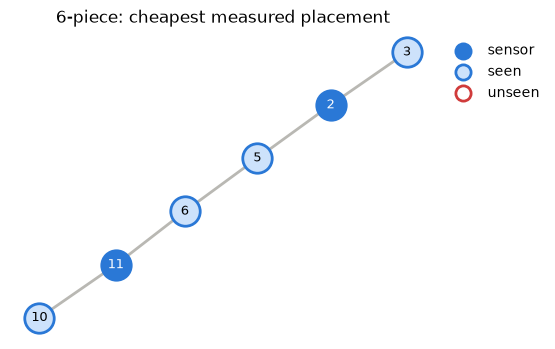

In [16]:
# 6-piece (original): defines layers6, P6, params6, probs6 used by the cells below
# hyperparams
layers6 = 1     # keep 1 for hardware: a short circuit
P6 = 2
SHOTS = 1000

# run circuit
t0 = time.perf_counter()
params6, counts6, best6 = run_qaoa_sampled(piece, layers=layers6, P=P6, shots=SHOTS)
probs6 = counts_to_probs(piece, counts6)   # only for the outcome charts below
print(f"6-piece: {time.perf_counter() - t0:.1f} s, angles {np.round(params6, 3)}")

# aggregate results
print("Cheapest measured placement:", best6, "| ILP answer:", ilp_placement(piece))
shots6 = sum(counts6.values())
for idx, (bits, c) in enumerate(sorted(counts6.items(), key=lambda kv: -kv[1])[:15]):   # most measured answers: not all are valid
    buses = bits_to_buses(piece, bits)
    r = check_placement(piece, buses, show=False)
    print(f"{str(idx).ljust(10)}  {c / shots6:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

draw_grid(piece, best6, "6-piece: cheapest measured placement")

6-piece (exact tuning): 2.9 s, angles [-1.571  0.5  ]
0           21.1%  sensors at [2, 11]  ->  valid
1           9.9%  sensors at [6, 11]  ->  NOT valid: buses [2, 3] unseen
2           9.9%  sensors at [2, 5]  ->  NOT valid: buses [10, 11] unseen
3           6.6%  sensors at [6, 10]  ->  NOT valid: buses [2, 3] unseen
4           6.6%  sensors at [3, 5]  ->  NOT valid: buses [10, 11] unseen
5           4.1%  sensors at [2, 5, 6, 11]  ->  valid
6           2.8%  sensors at [3, 5, 11]  ->  valid
7           2.8%  sensors at [3, 6, 11]  ->  valid
8           2.8%  sensors at [2, 6, 10]  ->  valid
9           2.8%  sensors at [2, 5, 10]  ->  valid


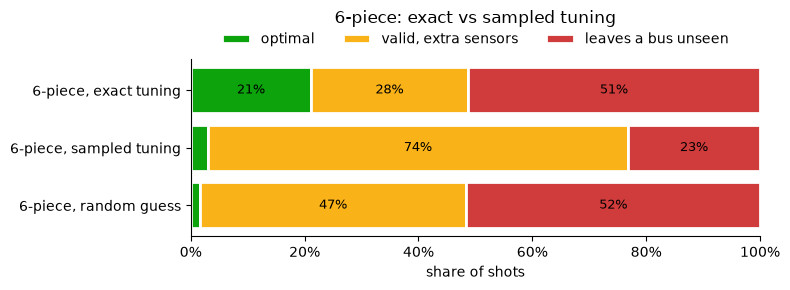

6-piece, exact tuning       optimal: 21.14%  valid, extra sensors: 27.52%  leaves a bus unseen: 51.34%
6-piece, sampled tuning     optimal:  3.00%  valid, extra sensors: 73.80%  leaves a bus unseen: 23.20%
6-piece, random guess       optimal:  1.56%  valid, extra sensors: 46.88%  leaves a bus unseen: 51.56%


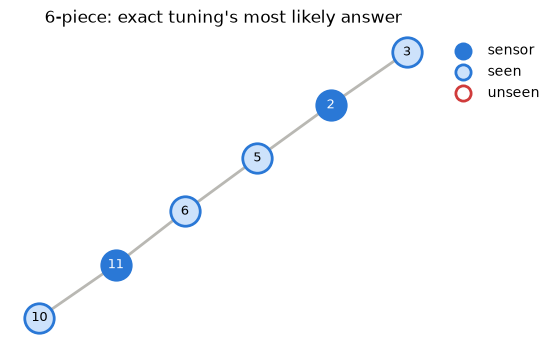

In [17]:
# Same run with the old exact tuning (run_qaoa: cost table + statevector). Separate names, so the sampled results stay.
t0 = time.perf_counter()
params6_exact, probs6_exact = run_qaoa(piece, layers=layers6, P=P6)
print(f"6-piece (exact tuning): {time.perf_counter() - t0:.1f} s, angles {np.round(params6_exact, 3)}")
for idx, z in enumerate(np.argsort(probs6_exact)[::-1][:10]):   # most likely answers: not all are valid
    buses = bits_to_buses(piece, format(z, '06b')[::-1])
    r = check_placement(piece, buses, show=False)
    print(f"{str(idx).ljust(10)}  {probs6_exact[z]:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

plot_outcomes({
    "6-piece, exact tuning": outcome_shares(piece, probs6_exact),
    "6-piece, sampled tuning": outcome_shares(piece, probs6),
    "6-piece, random guess": outcome_shares(piece, np.full(2 ** 6, 2.0 ** -6)),
}, "6-piece: exact vs sampled tuning")
draw_grid(piece, bits_to_buses(piece, format(np.argsort(probs6_exact)[::-1][0], '06b')[::-1]), "6-piece: exact tuning's most likely answer")

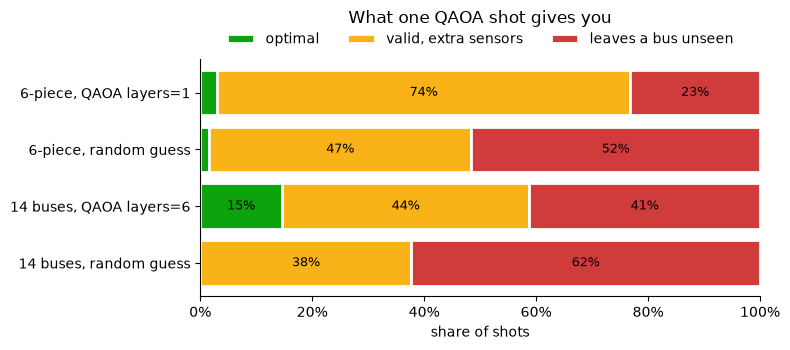

6-piece, QAOA layers=1      optimal:  3.00%  valid, extra sensors: 73.80%  leaves a bus unseen: 23.20%
6-piece, random guess       optimal:  1.56%  valid, extra sensors: 46.88%  leaves a bus unseen: 51.56%
14 buses, QAOA layers=6     optimal: 14.60%  valid, extra sensors: 44.20%  leaves a bus unseen: 41.20%
14 buses, random guess      optimal:  0.03%  valid, extra sensors: 37.70%  leaves a bus unseen: 62.27%


In [18]:
n6, n14 = len(piece["buses"]), len(grid["buses"])
plot_outcomes({
    f"6-piece, QAOA layers={layers6}": outcome_shares(piece, probs6),
    "6-piece, random guess": outcome_shares(piece, np.full(2 ** n6, 2.0 ** -n6)),
    f"14 buses, QAOA layers={layers14}": outcome_shares(grid, probs14),
    "14 buses, random guess": outcome_shares(grid, np.full(2 ** n14, 2.0 ** -n14)),
}, "What one QAOA shot gives you")

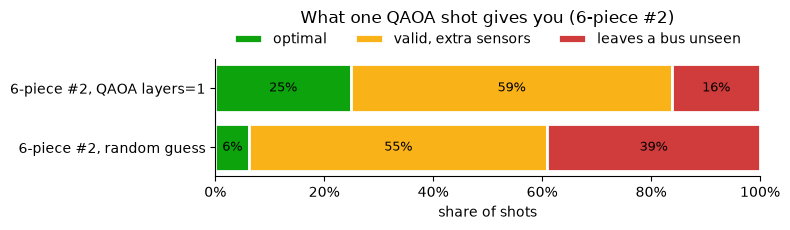

6-piece #2, QAOA layers=1   optimal: 24.90%  valid, extra sensors: 59.00%  leaves a bus unseen: 16.10%
6-piece #2, random guess    optimal:  6.25%  valid, extra sensors: 54.69%  leaves a bus unseen: 39.06%


In [19]:
n6_2 = len(piece6_2["buses"])
plot_outcomes({
    f"6-piece #2, QAOA layers={layers6_2}": outcome_shares(piece6_2, probs6_2),
    "6-piece #2, random guess": outcome_shares(piece6_2, np.full(2 ** n6_2, 2.0 ** -n6_2)),
}, "What one QAOA shot gives you (6-piece #2)")

## Milestone 5: run the 6-substation piece on IonQ

1. Run the cell below as is. It sends your tuned 6-piece circuit to IonQ's **free** simulator with IonQ's gate-noise model for Forte (`forte-1`). Compare settings there (for example `layers6 = 1` vs `2`, or `alpha`) before you spend credits.
2. When you're happy, swap in the IonQ Forte QPU lines and run once at **200 shots or fewer**. Queues can take hours, so send it early.
3. Recommended, and free: run the same circuit on Quantinuum's H2 emulator too (the cell has the lines) and compare its noise with IonQ's. Before you switch devices, save the result you have (for example `counts_ionq_sim = counts`) so you can chart both.
4. Copy each job ID into your run record. If the queue is stuck, keep the job ID and your noisy-simulator result to show the judges, and ask a qBraid mentor about a backup device.

In [20]:
# --- Run on a quantum computer through qBraid ---
import json
import warnings
from qbraid.runtime import QbraidProvider

def run_on_device(graph_id, device, output_id = None, runtime_options = dict(), shots = 200):

    # grid, tuned angles and penalty for each choice (from the QAOA cells above)
    runs = {
        "6": (piece, lambda: params6, lambda: P6),
        "6_2": (piece6_2, lambda: params6_2, lambda: P6_2),
        "14": (grid, lambda: params14, lambda: P14)
    }
    g_run, get_params, get_P = runs[graph_id]
    params_run, P_run = get_params(), get_P()   # lambdas: only the chosen grid's QAOA cell has to have run
    
    qc = qaoa_circuit(g_run, params_run, measure=True, P=P_run)
    qc = qc.assign_parameters({p: float(p) for p in qc.parameters})   # plain Python floats for qBraid
    qc = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
    print(f"Grid {graph_id} | qubits:", qc.num_qubits, "| two-qubit (CX) gates:", qc.count_ops()["cx"], "(IonQ advises a few dozen at most)")
    # qBraid may warn that measurements are ignored: IonQ always measures every qubit, so that's fine
    
    warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway
    
    provider = QbraidProvider()   # in qBraid Lab this uses your account automatically

    # put job on device
    device = provider.get_device(device)
    job = device.run(qc, shots=shots, runtime_options=runtime_options)
    
    print("Device:", device.id, "| Job ID:", job.id)   # copy both into your run record
    counts = job.result().data.get_counts()
    ranked = sorted(counts.items(), key=lambda kv: -kv[1])
    
    # save every outcome as bus numbers (key[::-1] switches Qiskit's bit order to ours)
    outcomes = [{"pmus": bits_to_buses(g_run, key.replace(" ", "")[::-1]), "count": c} for key, c in ranked]
    
    # save outcomes to file if asked
    if output_id is not None:
        with open(f"job_{output_id}_{job.id[-8:]}_counts.json", "w") as fl:
            json.dump(outcomes, fl)
    
    print("Most common results:", dict(ranked[:5]))



## Run 14 node problem on noiseless simulator

In [21]:

ID = "14"
DEVICE = "ionq:ionq:sim:simulator"
OUTPUT_ID = "14_sim"

run_on_device(ID, DEVICE, OUTPUT_ID, runtime_options = {"noise_model": "forte-1"}, shots=200)


Grid 14 | qubits: 14 | two-qubit (CX) gates: 2028 (IonQ advises a few dozen at most)
Device: ionq:ionq:sim:simulator | Job ID: ionq:ionq:sim:simulator-a10a-qjob-6af99ac227eb7437b2fedd80
Most common results: {'00000011011110': 1, '00000100001001': 1, '00000100111111': 1, '00000101001111': 1, '00000101011011': 1}


### Rigetti Cepheus QPU (AWS): 6-piece #2
Uses the 6-piece #2 angles from whichever 6-piece #2 cell ran last (the sampled one, if you run top to bottom). Costs credits.

In [22]:
# REAL QPU RUN for the second 6-piece (6_2). This uses credits: check the price and queue first.
ID = "6_2"
g_run = piece6_2
qc = qaoa_circuit(g_run, params6_2, measure=True, P=P6_2)
qc = qc.assign_parameters({p: float(p) for p in qc.parameters})   # plain Python floats for qBraid
qc = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
print(f"Grid {ID} | qubits:", qc.num_qubits, "| two-qubit (CX) gates:", qc.count_ops()["cx"], "(IonQ advises a few dozen at most)")

import json
import warnings
from qbraid.runtime import QbraidProvider
warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway

provider = QbraidProvider()
device = provider.get_device("aws:rigetti:qpu:cepheus-1-108q")    # aws:ionq:qpu:forte-1 showed UNAVAILABLE on Nov 14; switch back if it comes online
print("Device:", device.id, "| status:", device.status())
job = device.run(qc, shots=200)
print("Device:", device.id, "| Job ID:", job.id)   # copy both into your run record

counts = job.result().data.get_counts()   # waits for the QPU queue: this can take hours
counts_qpu_6_2 = counts                    # kept separately so later runs don't overwrite it
ranked = sorted(counts.items(), key=lambda kv: -kv[1])

# save every outcome as bus numbers (key[::-1] switches Qiskit's bit order to ours)
outcomes = [{"pmus": bits_to_buses(g_run, key.replace(" ", "")[::-1]), "count": c} for key, c in ranked]
with open(f"job_6_2_real_qpu_{job.id[-8:]}_counts.json", "w") as fl:
    json.dump(outcomes, fl)

print("Most common results:", dict(ranked[:5]))

Grid 6_2 | qubits: 6 | two-qubit (CX) gates: 122 (IonQ advises a few dozen at most)
Device: aws:rigetti:qpu:cepheus-1-108q | status: DeviceStatus.ONLINE
Device: aws:rigetti:qpu:cepheus-1-108q | Job ID: aws:rigetti:qpu:cepheus-1-108q-a10a-qjob-6af99b0b27eb7437b2fedd9b
Most common results: {'011111': 11, '100101': 8, '101100': 7, '111101': 7, '001001': 6}


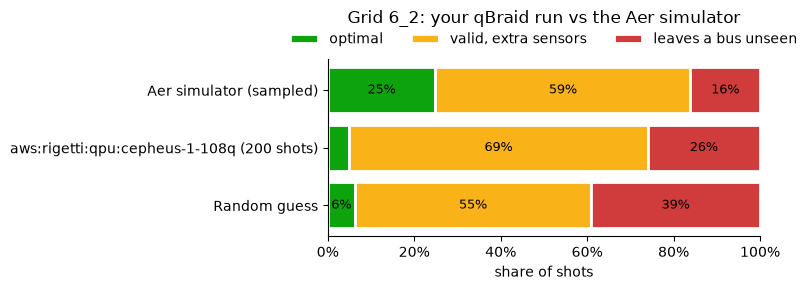

Aer simulator (sampled)     optimal: 24.90%  valid, extra sensors: 59.00%  leaves a bus unseen: 16.10%
aws:rigetti:qpu:cepheus-1-108q (200 shots)optimal:  5.00%  valid, extra sensors: 69.00%  leaves a bus unseen: 26.00%
Random guess                optimal:  6.25%  valid, extra sensors: 54.69%  leaves a bus unseen: 39.06%
Most common answer in your qBraid run: sensors at [1, 2, 3, 4, 5]


In [23]:
n_run = len(g_run["buses"])
probs_ideal = {"6": lambda: probs6, "6_2": lambda: probs6_2, "14": lambda: probs14}[ID]()
probs_hw = np.zeros(2 ** n_run)
for key, c in counts.items():
    probs_hw[int(key.replace(" ", ""), 2)] += c   # int(key, 2) reads Qiskit's order: bit i is qubit i
probs_hw /= probs_hw.sum()

plot_outcomes({
    "Aer simulator (sampled)": outcome_shares(g_run, probs_ideal),
    f"{device.id} ({sum(counts.values())} shots)": outcome_shares(g_run, probs_hw),
    "Random guess": outcome_shares(g_run, np.full(2 ** n_run, 2.0 ** -n_run)),
}, f"Grid {ID}: your qBraid run vs the Aer simulator")
top = max(counts, key=counts.get)
print("Most common answer in your qBraid run: sensors at", bits_to_buses(g_run, top.replace(" ", "")[::-1]))

## Post-Processing of QAOA Data

Data from one of our QAOA runs was output to a .json file, which is called below. This set of code processes the large set of QAOA output to find the sensor configuration solution that is most optimal.

Steps:
1. Filter solutions to only show ones that cover all system buses with PMU sensor detection
2. For each number of PMUs that can accomplish this, choose the QAOA solution that provides the most redundancy, prioritizing coverage of buses with large MW loads
3. Output the optimal results per number of sensors used to a visualization, showing the redundancy that can be gained per sensor and cost

In the visual output below, use the "+"/"-" at below the graph to change the number of sensors used on the system and see how redudancy increases.

In [24]:
# Imports
import importlib, json, os
from pathlib import Path
import visualization
importlib.reload(visualization)   # picks up edits to visualization.py without restarting the kernel

# Settings for input files
GRID_FILE = "data/ieee14.json"       # select grid bus configuration
PLACEMENTS_FILE = "14simdata.json"   # all possible sensor placements generated by QAOA
COST_PER_PMU = 100_000               # each PMU costs $100,000
MAX_PMUS = 8                         # only consider placements with <= this many PMUs

# Check that all needed data is present in the current folder
for fname in (GRID_FILE, PLACEMENTS_FILE):
    if not Path(fname).exists():
        raise FileNotFoundError(
            f"{fname} not found in {os.getcwd()}. Upload it to the same folder as this notebook.")

# Load grid data from chosen IEEE configuration file
config = json.loads(Path(GRID_FILE).read_text())
buses = config["buses"]
lines = [tuple(l) for l in config["lines"]]
load_mw = {int(k): v for k, v in config["load_mw"].items()}

# Adjacent nodes
neighbors = {b: set() for b in buses}
for a, b in lines:
    neighbors[a].add(b)
    neighbors[b].add(a)

# Weight each bus by its load
weights = {b: (load_mw.get(b, 0) or 1) for b in buses}
total_weight = sum(weights.values())

def sightings(chosen):
    """How many PMUs see each bus. A PMU sees its own bus and every bus one line away."""
    chosen = set(chosen)
    seen = {b: 0 for b in buses}
    for p in chosen:
        seen[p] += 1
        for n in neighbors[p]:
            seen[n] += 1
    return seen

# Read all sensor placements generated by QAOA
placements_raw = json.loads(Path(PLACEMENTS_FILE).read_text())
placements = [p["pmus"] if isinstance(p, dict) else p for p in placements_raw]

# Score each placement
results = []
for pmus in placements:
    seen = sightings(pmus)
    is_valid = all(seen[b] >= 1 for b in buses)
    doubly = [b for b in buses if seen[b] >= 2]
    pct = round(100 * sum(weights[b] for b in doubly) / total_weight, 1)
    results.append({"pmus": list(pmus), "isValid": is_valid, "percentRedundancy": pct})

# Keep only valid placements, grouped by PMU count
valid_by_count = {}
for r in results:
    k = len(r["pmus"])
    if r["isValid"] and k <= MAX_PMUS:
        valid_by_count.setdefault(k, []).append(r)

# Best (most redundant) valid placement for each PMU count
entries = [max(valid_by_count[c], key=lambda r: r["percentRedundancy"])
           for c in sorted(valid_by_count)]

if not entries:
    raise ValueError(f"No valid placement with {MAX_PMUS} or fewer PMUs in {PLACEMENTS_FILE}.")

all_counts = range(min(valid_by_count), MAX_PMUS + 1)
skipped = [c for c in all_counts if c not in valid_by_count]
print(f"Grid: {GRID_FILE}")
print(f"Kept {len(entries)} entries, one per PMU count: {[len(e['pmus']) for e in entries]}")
print(f"Skipped PMU counts with no valid placement: {skipped}")

# Hand everything the visualization needs to the other file
visualization.drawEverything(buses, lines, entries, sightings, COST_PER_PMU)

Grid: data/ieee14.json
Kept 5 entries, one per PMU count: [4, 5, 6, 7, 8]
Skipped PMU counts with no valid placement: []
